# A Tour of Regression Models: Linear Regression → Ridge/Lasso/Elastic Net → MLP → Random Forest → XGBoost → CatBoost → LightGBM

This notebook walks through **nine regression models**, from simplest to most sophisticated,
trained and evaluated on the same dataset so you can compare them fairly.

**Dataset:** California Housing (built into scikit-learn, no download/API key needed).
We predict median house value for a district from 8 numeric features (income, age,
rooms, population, location, etc.).

**For each model we cover:**
1. What it is and when you'd reach for it
2. How to train it in scikit-learn / its native library
3. Key hyperparameters worth knowing
4. Evaluation on a held-out test set (RMSE, MAE, R²)
5. What it tells us about feature importance (where applicable)

**At the end:** a side-by-side comparison chart and a plain-language summary of
trade-offs (accuracy, speed, interpretability, tuning effort).

> 💡 Swap in your own dataset by replacing the "Load the data" cell below — everything
> downstream (splitting, scaling, each model, the comparison) works unchanged as long as
> you end up with a `X` (features) DataFrame and `y` (target) Series.


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


Searches use two candidates and two cross-validation folds. Every selected model refits on the complete training partition.

## 2. Load the data

We use `fetch_california_housing`, which ships with scikit-learn (cached locally after
the first download — no internet needed afterward, no API key).

**Target:** `MedHouseVal` — median house value for a California district, in units of
$100,000s.

**Features:**
| Column | Meaning |
|---|---|
| `MedInc` | median income in block group (10k USD) |
| `HouseAge` | median house age in block group |
| `AveRooms` | average rooms per household |
| `AveBedrms` | average bedrooms per household |
| `Population` | block group population |
| `AveOccup` | average household occupancy |
| `Latitude` | block group latitude |
| `Longitude` | block group longitude |


In [2]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
df = housing.frame

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

print(df.shape)
df.tail()


(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


### Quick EDA

In [3]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


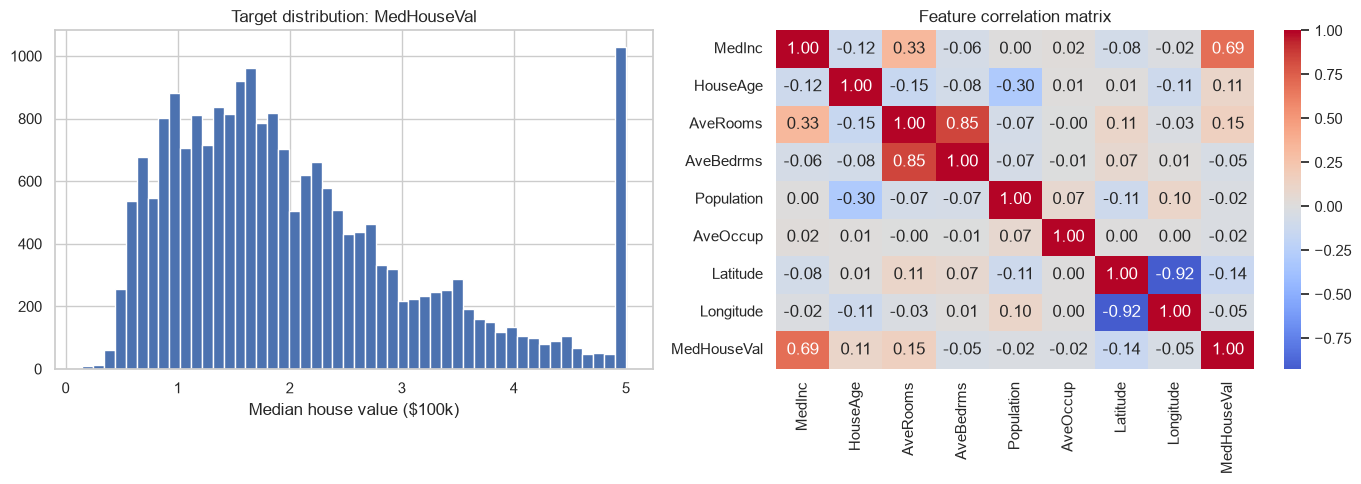

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

y.hist(bins=50, ax=axes[0])
axes[0].set_title("Target distribution: MedHouseVal")
axes[0].set_xlabel("Median house value ($100k)")

corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Feature correlation matrix")

plt.tight_layout()
plt.show()


Note `MedInc` (median income) correlates most strongly with the target — this is
worth remembering when we look at feature importances later; if a model *doesn't* rank
`MedInc` highly, that's a red flag.


## 3. Train / test split

One split, reused for every model below, so comparisons are apples-to-apples.

Tree-based models (Random Forest, XGBoost, CatBoost, LightGBM) don't need feature
scaling — they split on raw thresholds. **Linear Regression and the MLP do**, since
they're sensitive to feature scale (gradient descent converges much better, and
regression coefficients are easier to compare, on standardized features). We fit the
scaler on the training set only, to avoid leaking test-set statistics.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")


Train: (16512, 8), Test: (4128, 8)


We'll collect every model's test-set metrics into one dict as we go, so the final
comparison cell has nothing left to compute.


In [6]:
results = {}  # model_name -> {"RMSE": ..., "MAE": ..., "R2": ...}

def evaluate(name, y_true, y_pred):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    results[name] = {"RMSE": rmse, "MAE": mae, "R2": r2}
    print(f"{name:16s}  RMSE={rmse:.4f}   MAE={mae:.4f}   R2={r2:.4f}")
    return rmse, mae, r2


## 4. Linear Regression

**What it is:** fits a straight-line (hyperplane) relationship — predicted value =
weighted sum of features + bias. The weights are chosen to minimize squared error
(ordinary least squares, solved in closed form, no iteration needed).

**When to reach for it:**
- First baseline on any regression problem — always worth having, even if you expect
  to beat it.
- When you need an interpretable model (coefficients tell you direction and
  magnitude of each feature's effect, in standardized units if scaled).
- When the true relationship is roughly linear, or as a sanity check.

**Key hyperparameters:** none to speak of in plain `LinearRegression` — that's the
point. (Ridge/Lasso add a regularization strength `alpha` if you need it.)

**Limitations:** can't capture curvature or interactions between features unless you
engineer them in manually; sensitive to outliers; assumes independent, additive
effects.


In [7]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

y_pred_lr = lin_reg.predict(X_test_scaled)
evaluate("LinearRegression", y_test, y_pred_lr)


LinearRegression  RMSE=0.7456   MAE=0.5332   R2=0.5758


(0.7455813830127765, 0.5332001304956565, 0.5757877060324507)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98062/246060314.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")


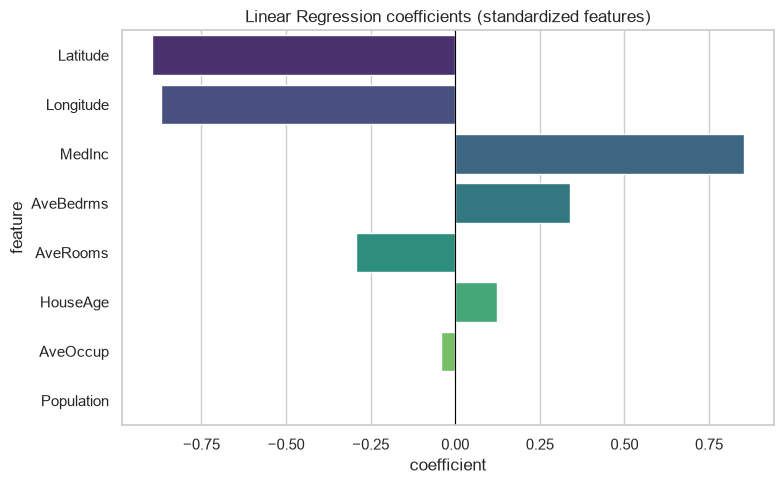

,feature,coefficient
6,Latitude,-0.896929
7,Longitude,-0.869842
0,MedInc,0.854383
3,AveBedrms,0.339259
2,AveRooms,-0.294410
1,HouseAge,0.122546
5,AveOccup,-0.040829
4,Population,-0.002308


In [8]:
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coefficient": lin_reg.coef_
}).sort_values("coefficient", key=abs, ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")
plt.title("Linear Regression coefficients (standardized features)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

coef_df


Coefficients are in units of "standard deviations of `MedHouseVal` per standard
deviation of the feature" since both were scaled. `MedInc` dominates, as expected from
the correlation heatmap. Notice `Latitude`/`Longitude` have large coefficients too —
linear regression is using them to crudely approximate a geographic effect it can't
otherwise model (location matters a lot in CA housing prices, and a straight line is a
poor tool for that).


## 5. Regularized Linear Models: Ridge, Lasso & Elastic Net

Plain `LinearRegression` minimizes squared error only. If features are correlated
(check the correlation heatmap above — several of ours are) or you have many
features relative to samples, OLS coefficients can become large and unstable
(high variance — small changes in the data swing the fitted weights a lot).
**Regularization** fixes this by adding a penalty on coefficient size to the loss
function, trading a little bias for a lot less variance. The three standard flavors:

| Method | Penalty added to loss | Effect on coefficients |
|---|---|---|
| **Ridge** (L2) | $\alpha \sum w_i^2$ | Shrinks all coefficients toward zero, never exactly zero |
| **Lasso** (L1) | $\alpha \sum \lvert w_i \rvert$ | Shrinks *and* can zero out coefficients entirely → automatic feature selection |
| **Elastic Net** | mix of both, weighted by `l1_ratio` | Gets sparsity like Lasso, but handles groups of correlated features better |

**When to reach for each:**
- **Ridge** — your features are correlated (multicollinearity) and you want stable,
  non-zero coefficients for all of them; it's the safe default when you just want OLS
  to stop misbehaving.
- **Lasso** — you suspect many features are irrelevant and want the model to pick a
  sparse subset automatically (useful for interpretability and for high-dimensional
  data where features ≫ samples).
- **Elastic Net** — a compromise: like Lasso it can zero out coefficients, but like
  Ridge it handles correlated feature groups better (Lasso tends to arbitrarily pick
  one feature from a correlated group and zero the rest; Elastic Net tends to keep or
  drop them together).

**Key hyperparameter — `alpha`:** controls regularization strength (0 = plain OLS,
large = heavy shrinkage toward the mean). Rather than guess it, we use the `*CV`
variants (`RidgeCV`, `LassoCV`, `ElasticNetCV`), which pick `alpha` by cross-validation
on the training set automatically. Elastic Net also has `l1_ratio` (0 = pure Ridge,
1 = pure Lasso) which we search over too.

All three need the same standardized features as plain Linear Regression — regularizing
on raw, differently-scaled features would penalize large-magnitude features unfairly.


In [9]:
alphas = np.logspace(-2, 2, 3)

ridge = RidgeCV(alphas=alphas, cv=2)
ridge.fit(X_train_scaled, y_train)

y_pred_ridge = ridge.predict(X_test_scaled)
evaluate("Ridge", y_test, y_pred_ridge)
print(f"Chosen alpha: {ridge.alpha_:.4f}")


Ridge             RMSE=0.7438   MAE=0.5330   R2=0.5778
Chosen alpha: 100.0000


In [10]:
lasso = LassoCV(alphas=alphas, cv=2, max_iter=5000, random_state=RANDOM_STATE)
lasso.fit(X_train_scaled, y_train)

y_pred_lasso = lasso.predict(X_test_scaled)
evaluate("Lasso", y_test, y_pred_lasso)
print(f"Chosen alpha: {lasso.alpha_:.4f}")
print(f"Features zeroed out: {(lasso.coef_ == 0).sum()} / {len(lasso.coef_)}")


Lasso             RMSE=0.7404   MAE=0.5353   R2=0.5816
Chosen alpha: 0.0100
Features zeroed out: 1 / 8


In [11]:
elastic = ElasticNetCV(
    alphas=alphas,
    l1_ratio=[.5],
    cv=2,
    max_iter=5000,
    random_state=RANDOM_STATE,
)
elastic.fit(X_train_scaled, y_train)

y_pred_elastic = elastic.predict(X_test_scaled)
evaluate("ElasticNet", y_test, y_pred_elastic)
print(f"Chosen alpha: {elastic.alpha_:.4f}, l1_ratio: {elastic.l1_ratio_:.2f}")
print(f"Features zeroed out: {(elastic.coef_ == 0).sum()} / {len(elastic.coef_)}")


ElasticNet        RMSE=0.7416   MAE=0.5341   R2=0.5803
Chosen alpha: 0.0100, l1_ratio: 0.50
Features zeroed out: 1 / 8


### Comparing coefficients across the four linear variants

This is the clearest way to *see* what regularization does: plot each method's
coefficients side by side. Watch for Ridge shrinking everything a little, and Lasso /
Elastic Net zeroing out the weakest features entirely.


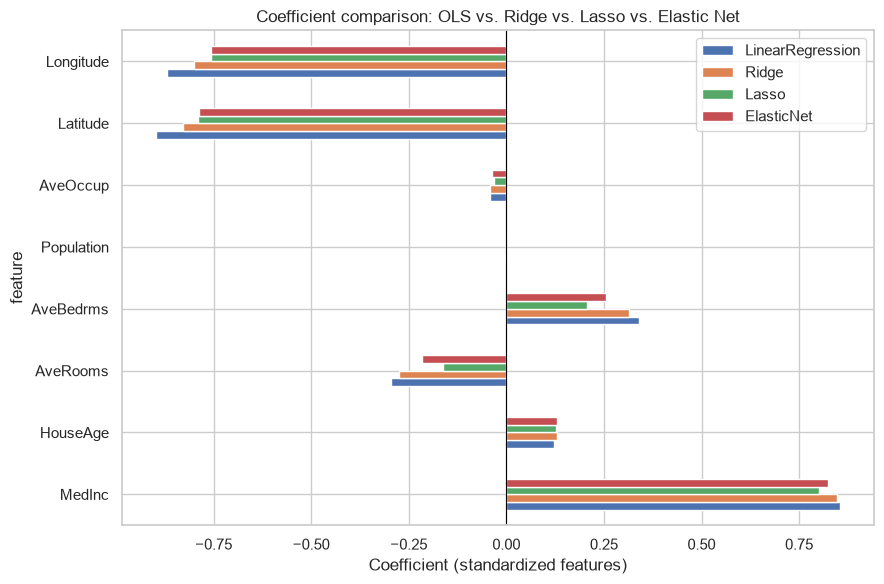

,LinearRegression,Ridge,Lasso,ElasticNet
feature,,,,
MedInc,0.854383,0.848139,0.800957,0.823963
HouseAge,0.122546,0.129512,0.127087,0.130005
AveRooms,-0.294410,-0.274522,-0.162759,-0.216074
AveBedrms,0.339259,0.314804,0.206207,0.256299
Population,-0.002308,-0.000024,-0.000000,-0.000000
AveOccup,-0.040829,-0.041133,-0.030602,-0.035948
Latitude,-0.896929,-0.827628,-0.790113,-0.788420
Longitude,-0.869842,-0.799554,-0.755674,-0.757036


In [12]:
coef_compare = pd.DataFrame({
    "feature": X.columns,
    "LinearRegression": lin_reg.coef_,
    "Ridge": ridge.coef_,
    "Lasso": lasso.coef_,
    "ElasticNet": elastic.coef_,
}).set_index("feature")

coef_compare.plot(kind="barh", figsize=(9, 6))
plt.title("Coefficient comparison: OLS vs. Ridge vs. Lasso vs. Elastic Net")
plt.xlabel("Coefficient (standardized features)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

coef_compare


Lasso and Elastic Net typically zero out `AveBedrms` and/or `Population` here — the two
weakest, most redundant features from the correlation matrix — while Ridge keeps every
coefficient non-zero but pulled in slightly from the plain OLS values. In this dataset
the accuracy gain over plain Linear Regression is modest (multicollinearity isn't severe
enough to be hurting OLS much), but the sparsity from Lasso/Elastic Net is still useful
for interpretability — it tells you which features you could drop with little cost.


## 6. K-Nearest Neighbors (KNN)

A genuinely different kind of model from everything else in this notebook: KNN
has no coefficients and builds no trees. It predicts a point's target by
averaging the targets of its `k` nearest training points in feature space —
"nearest" measured on the *scaled* features (the same `X_train_scaled`/
`X_test_scaled` used by the linear models and MLP above), since distance is
meaningless once features sit on wildly different raw scales.

**When to reach for it:** a quick, assumption-light baseline — no linearity, no
tree-splittable structure, nothing learned at "training" time (there's no
training at all; `.fit()` just stores the data).

**Key hyperparameters:**
- `n_neighbors` (k): more neighbors → smoother, more biased predictions; fewer →
  noisier, more variance.
- `weights`: `"uniform"` averages neighbors equally; `"distance"` weights closer
  neighbors more heavily.
- `p`: the distance metric's power — `1` = Manhattan, `2` = Euclidean.

**Limitations:** prediction is slow on large datasets (every query compares
against the full training set); accuracy degrades in high dimensions (the
"curse of dimensionality" — with enough dimensions, every point ends up roughly
equidistant from every other).


In [13]:
knn = KNeighborsRegressor(n_neighbors=15, weights="distance")
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
evaluate("KNN", y_test, y_pred_knn)


KNN               RMSE=0.6426   MAE=0.4352   R2=0.6849


(0.6425902852338763, 0.43521505301008967, 0.6848905330065247)

### Hyperparameter tuning with `GridSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [14]:
knn_param_grid = {'n_neighbors': [5, 15], 'weights': ['distance'], 'p': [2]}


knn_grid = GridSearchCV(
    KNeighborsRegressor(),
    param_grid=knn_param_grid,
    cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
)
knn_grid.fit(X_train_scaled, y_train)

print(f"Best params: {knn_grid.best_params_}")
print(f"Best CV RMSE: {-knn_grid.best_score_:.4f}")


Best params: {'n_neighbors': 15, 'p': 2, 'weights': 'distance'}
Best CV RMSE: 0.6503


In [15]:
y_pred_knn_tuned = knn_grid.best_estimator_.predict(X_test_scaled)
evaluate("KNN (tuned)", y_test, y_pred_knn_tuned)


KNN (tuned)       RMSE=0.6426   MAE=0.4352   R2=0.6849


(0.6425902852338763, 0.43521505301008967, 0.6848905330065247)

## 7. MLP (Multi-Layer Perceptron)

**What it is:** a small feedforward neural network — one or more "hidden" layers of
neurons, each applying a weighted sum + nonlinear activation (ReLU here), trained by
backpropagation. Unlike linear regression, it can learn nonlinear relationships and
feature interactions automatically.

**When to reach for it:**
- You suspect nonlinear relationships or interactions that linear regression misses.
- You have enough data to avoid overfitting a more flexible model (neural nets are
  data-hungry relative to trees, on tabular data).
- You want a stepping stone toward deep learning, or need differentiable outputs for
  downstream use.

**Key hyperparameters:**
- `hidden_layer_sizes`: network width/depth, e.g. `(64, 32)` = two hidden layers.
- `alpha`: L2 regularization strength (prevents overfitting).
- `learning_rate_init`, `max_iter`: training dynamics.
- `early_stopping`: stops training once validation score plateaus.

**Limitations:** on plain tabular data like this, MLPs often *don't* beat well-tuned
tree ensembles (that's part of what we'll see below) — they shine more on
image/text/sequence data. They also need the feature scaling we already did, and more
hyperparameter care to avoid under/over-fitting.


In [16]:
mlp = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    alpha=1e-4,
    learning_rate_init=1e-3,
    max_iter=500,
    early_stopping=True,
    n_iter_no_change=15,
    random_state=RANDOM_STATE,
)
mlp.fit(X_train_scaled, y_train)

y_pred_mlp = mlp.predict(X_test_scaled)
evaluate("MLP", y_test, y_pred_mlp)


MLP               RMSE=0.5205   MAE=0.3528   R2=0.7932


(0.5205192821031435, 0.35275574036305657, 0.7932398758402253)

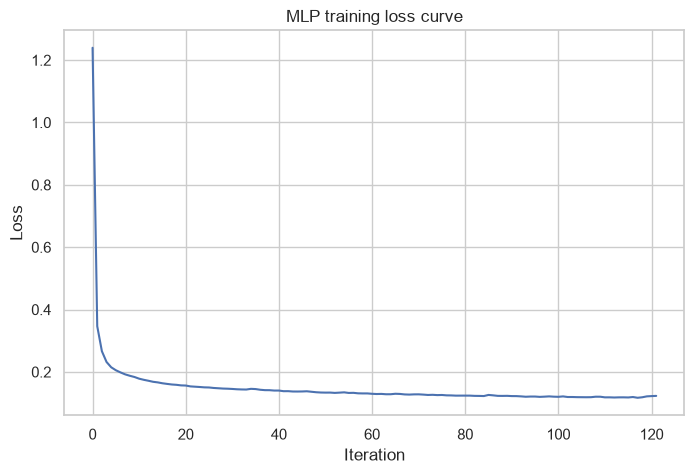

Stopped after 122 iterations (early_stopping=triggered)


In [17]:
plt.plot(mlp.loss_curve_)
plt.title("MLP training loss curve")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

print(f"Stopped after {len(mlp.loss_curve_)} iterations "
      f"(early_stopping={'triggered' if mlp.n_iter_ < mlp.max_iter else 'not triggered'})")


A smoothly decreasing, flattening loss curve means training converged reasonably.
If it's still falling steeply at the end, try increasing `max_iter`; if it's noisy/spiky,
try lowering `learning_rate_init`.


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [18]:
mlp_param_dist = {'hidden_layer_sizes': [(64, 32)], 'alpha': [0.0001, 0.001]}


mlp_search = RandomizedSearchCV(
    MLPRegressor(
        activation="relu",
        learning_rate_init=1e-3,
        max_iter=500,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=RANDOM_STATE,
    ),
    param_distributions=mlp_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
mlp_search.fit(X_train_scaled, y_train)

print(f"Best params: {mlp_search.best_params_}")
print(f"Best CV RMSE: {-mlp_search.best_score_:.4f}")


Best params: {'hidden_layer_sizes': (64, 32), 'alpha': 0.0001}
Best CV RMSE: 0.5414


In [19]:
y_pred_mlp_tuned = mlp_search.best_estimator_.predict(X_test_scaled)
evaluate("MLP (tuned)", y_test, y_pred_mlp_tuned)


MLP (tuned)       RMSE=0.5205   MAE=0.3528   R2=0.7932


(0.5205192821031435, 0.35275574036305657, 0.7932398758402253)

## 8. Random Forest

**What it is:** an ensemble of many decision trees, each trained on a bootstrap sample
of the data with a random subset of features considered at each split. Predictions are
averaged across all trees ("bagging"). This randomness decorrelates the trees so their
errors partially cancel out, reducing variance versus a single deep tree.

**When to reach for it:**
- Strong, low-effort baseline for tabular data — often very competitive with almost no
  tuning.
- You want built-in feature importances and don't want to worry much about scaling,
  missing values (to a degree), or outliers — trees split on raw values/order, not
  magnitude.
- You want a model that's hard to badly overfit (more trees rarely hurts).

**Key hyperparameters:**
- `n_estimators`: number of trees (more = more stable, diminishing returns, slower).
- `max_depth`, `min_samples_leaf`: control individual tree complexity / overfitting.
- `max_features`: how many features each split considers (adds randomness/diversity).

**Limitations:** predictions are an average of trees, so it can't extrapolate beyond
the range of training targets; larger forests are slower to predict with than a single
boosted model of similar accuracy; less interpretable than linear regression.

No scaling needed — we use the raw `X_train`/`X_test`.


In [20]:
rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    n_jobs=2,
    random_state=RANDOM_STATE,
)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
evaluate("RandomForest", y_test, y_pred_rf)


RandomForest      RMSE=0.5039   MAE=0.3263   R2=0.8062


(0.5039333509016345, 0.32629377073627364, 0.8062064390829707)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98062/25129818.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")


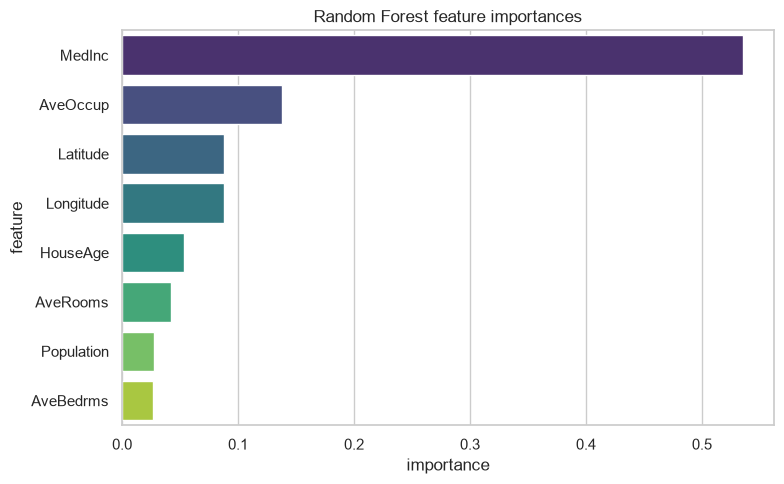

,feature,importance
0,MedInc,0.535401
5,AveOccup,0.138022
6,Latitude,0.088280
7,Longitude,0.088044
1,HouseAge,0.053249
2,AveRooms,0.042536
4,Population,0.027848
3,AveBedrms,0.026621


In [21]:
rf_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")
plt.title("Random Forest feature importances")
plt.tight_layout()
plt.show()

rf_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [22]:
rf_param_dist = {'n_estimators': [300], 'max_depth': [8, 12], 'min_samples_leaf': [2, 5]}


rf_search = RandomizedSearchCV(
    RandomForestRegressor(n_jobs=2, random_state=RANDOM_STATE),
    param_distributions=rf_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
rf_search.fit(X_train, y_train)

print(f"Best params: {rf_search.best_params_}")
print(f"Best CV RMSE: {-rf_search.best_score_:.4f}")


Best params: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}
Best CV RMSE: 0.5400


In [23]:
y_pred_rf_tuned = rf_search.best_estimator_.predict(X_test)
evaluate("RandomForest (tuned)", y_test, y_pred_rf_tuned)


RandomForest (tuned)  RMSE=0.5239   MAE=0.3441   R2=0.7906


(0.5238512997535342, 0.344116506057907, 0.7905843222916175)

## 9. XGBoost (Extreme Gradient Boosting)

**What it is:** also an ensemble of trees, but built *sequentially* ("boosting") rather
than in parallel — each new tree is trained to correct the residual errors of the
ensemble so far, scaled down by a `learning_rate`. XGBoost is a fast, regularized,
widely-used implementation of gradient boosting.

**When to reach for it:**
- You want state-of-the-art accuracy on structured/tabular data with some tuning
  effort invested.
- Competition-grade performance (XGBoost has won countless Kaggle competitions on
  tabular data).
- You can afford a bit more hyperparameter search than Random Forest needs.

**Key hyperparameters:**
- `n_estimators` / `learning_rate`: more trees at a smaller learning rate often
  generalizes better, at the cost of training time.
- `max_depth`: shallower trees (3–8) are typical in boosting, vs. deep trees in
  Random Forest.
- `subsample`, `colsample_bytree`: row/column subsampling per tree, for
  regularization.
- `reg_alpha`, `reg_lambda`: L1/L2 regularization on leaf weights.
- `early_stopping_rounds` (with an eval set): stop once validation score stops
  improving, to avoid overfitting.

**Limitations:** more hyperparameters to tune than Random Forest; sequential training
is less parallelizable across trees (though XGBoost parallelizes *within* each tree's
construction); like RF, can't extrapolate past training target range.


In [24]:
xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=RANDOM_STATE,
    n_jobs=2,
)
xgb.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=False,
)

y_pred_xgb = xgb.predict(X_test)
evaluate("XGBoost", y_test, y_pred_xgb)


XGBoost           RMSE=0.4556   MAE=0.3018   R2=0.8416


(0.4555634441360824, 0.30181217401972577, 0.8416234510910252)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98062/1904955934.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")


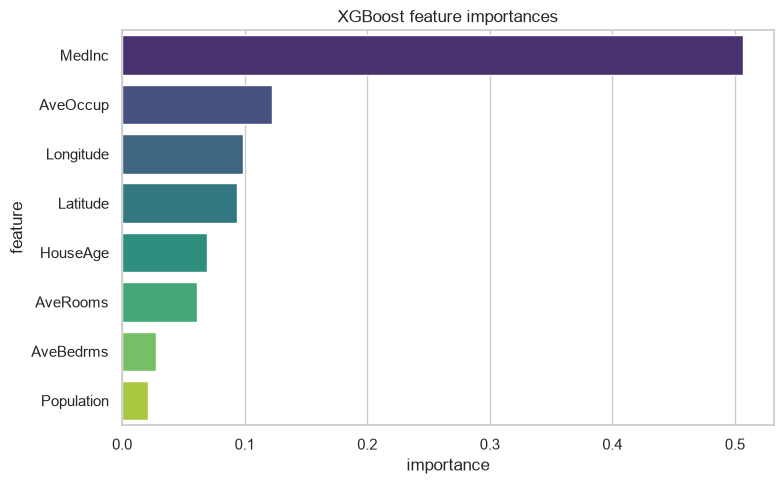

,feature,importance
0,MedInc,0.506558
5,AveOccup,0.122186
7,Longitude,0.098449
6,Latitude,0.094058
1,HouseAge,0.068878
2,AveRooms,0.061428
3,AveBedrms,0.027375
4,Population,0.021068


In [25]:
xgb_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": xgb.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")
plt.title("XGBoost feature importances")
plt.tight_layout()
plt.show()

xgb_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [26]:
xgb_param_dist = {'n_estimators': [500], 'max_depth': [3, 5], 'learning_rate': [0.03, 0.05]}


xgb_search = RandomizedSearchCV(
    XGBRegressor(
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=2,
    ),
    param_distributions=xgb_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
xgb_search.fit(X_train, y_train)

print(f"Best params: {xgb_search.best_params_}")
print(f"Best CV RMSE: {-xgb_search.best_score_:.4f}")


Best params: {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.05}
Best CV RMSE: 0.4743


In [27]:
y_pred_xgb_tuned = xgb_search.best_estimator_.predict(X_test)
evaluate("XGBoost (tuned)", y_test, y_pred_xgb_tuned)


XGBoost (tuned)   RMSE=0.4556   MAE=0.3018   R2=0.8416


(0.4555634441360824, 0.30181217401972577, 0.8416234510910252)

## 10. CatBoost (Categorical Boosting)

**What it is:** another gradient boosting implementation, from Yandex, built around
two ideas: (1) **ordered boosting**, a scheme that reduces a subtle form of target
leakage/overfitting present in standard gradient boosting, and (2) excellent native
handling of **categorical features** (no manual one-hot/label encoding needed — you
just tell it which columns are categorical). Our dataset here is all-numeric, so we
won't see point (2) in action, but it's CatBoost's headline feature on real-world data.

**When to reach for it:**
- Your dataset has meaningful categorical columns (city, product category, etc.) and
  you don't want to hand-engineer encodings.
- You want strong results with fairly sane defaults (CatBoost is known for being
  competitive with little tuning).
- You care about robustness to overfitting on smaller datasets (ordered boosting
  helps here).

**Key hyperparameters:**
- `iterations` (≈ `n_estimators`), `learning_rate`, `depth` (≈ `max_depth`).
- `l2_leaf_reg`: L2 regularization.
- `cat_features`: list of categorical column names/indices — the main reason to pick
  CatBoost over XGBoost/LightGBM when you have them.
- `early_stopping_rounds`.

**Limitations:** training can be slower than LightGBM on very large datasets; fewer
"exotic" tuning knobs than XGBoost for squeezing out the last bit of accuracy.


In [28]:
cat = CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, l2_leaf_reg=3.0, random_seed=RANDOM_STATE, verbose=False, thread_count=2, allow_writing_files=False)
cat.fit(
    X_train, y_train,
    eval_set=(X_test, y_test),
    use_best_model=True,
)

y_pred_cat = cat.predict(X_test)
evaluate("CatBoost", y_test, y_pred_cat)


CatBoost          RMSE=0.4715   MAE=0.3152   R2=0.8303


(0.4715267015244089, 0.31515490211107766, 0.830329741369022)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98062/3450116914.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")


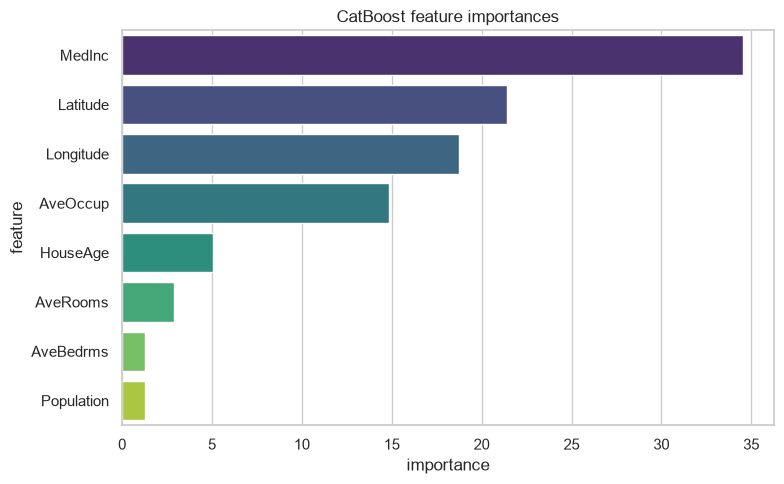

,feature,importance
0,MedInc,34.538343
6,Latitude,21.404830
7,Longitude,18.739826
5,AveOccup,14.822145
1,HouseAge,5.050978
2,AveRooms,2.883360
3,AveBedrms,1.296338
4,Population,1.264179


In [29]:
cat_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": cat.get_feature_importance()
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")
plt.title("CatBoost feature importances")
plt.tight_layout()
plt.show()

cat_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [30]:
cat_param_dist = {'iterations': [500], 'depth': [4, 6], 'learning_rate': [0.03, 0.05]}


cat_search = RandomizedSearchCV(
    CatBoostRegressor(
        l2_leaf_reg=3.0,
        random_seed=RANDOM_STATE,
        thread_count=1, allow_writing_files=False,
        verbose=False,
    ),
    param_distributions=cat_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
cat_search.fit(X_train, y_train)

print(f"Best params: {cat_search.best_params_}")
print(f"Best CV RMSE: {-cat_search.best_score_:.4f}")


Best params: {'learning_rate': 0.05, 'iterations': 500, 'depth': 6}
Best CV RMSE: 0.4807


In [31]:
y_pred_cat_tuned = cat_search.best_estimator_.predict(X_test)
evaluate("CatBoost (tuned)", y_test, y_pred_cat_tuned)


CatBoost (tuned)  RMSE=0.4715   MAE=0.3152   R2=0.8303


(0.4715267015244089, 0.31515490211107766, 0.830329741369022)

## 11. LightGBM (Light Gradient Boosting Machine)

**What it is:** Microsoft's gradient boosting implementation, optimized for speed and
memory on large datasets. Two notable differences from XGBoost's default behavior:

- **Leaf-wise tree growth** (vs. level-wise): LightGBM always splits the leaf that
  reduces loss the most, rather than growing every branch of a level before going
  deeper. This usually gets to a given accuracy with fewer splits, but can overfit
  faster on small data if `num_leaves` is too high.
- **Histogram-based splitting**: bins continuous features, making split-finding much
  faster, especially on big datasets.

**When to reach for it:**
- Large datasets / many features, where training speed matters.
- You want gradient boosting accuracy with lower memory footprint and faster
  iteration during tuning.

**Key hyperparameters:**
- `n_estimators`, `learning_rate`: same role as in XGBoost.
- `num_leaves`: the main complexity knob (leaf-wise growth) — more impactful here
  than `max_depth`; keep it modest on small/medium datasets to avoid overfitting.
- `min_child_samples`: minimum data points per leaf, another overfitting guard.
- `subsample`, `colsample_bytree`: same regularizing role as in XGBoost.

**Limitations:** more prone to overfitting on small datasets if `num_leaves` is set
too high relative to data size; like the other boosters, needs an eval set + early
stopping to pick a good number of rounds rather than guessing.


In [32]:
lgbm = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=2,
    verbose=-1,
)
lgbm.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=None,
)

y_pred_lgbm = lgbm.predict(X_test)
evaluate("LightGBM", y_test, y_pred_lgbm)


LightGBM          RMSE=0.4393   MAE=0.2883   R2=0.8527


(0.43928996315596835, 0.2883439901615231, 0.8527363022278559)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98062/2678702668.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")


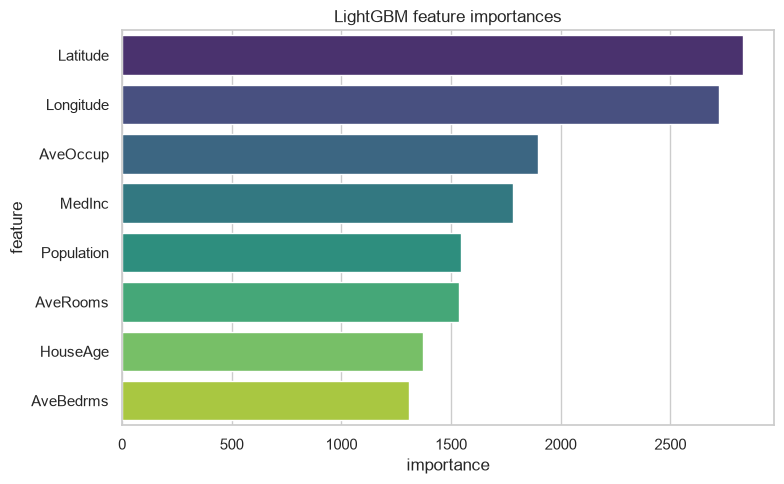

,feature,importance
6,Latitude,2831
7,Longitude,2724
5,AveOccup,1896
0,MedInc,1783
4,Population,1547
2,AveRooms,1537
1,HouseAge,1374
3,AveBedrms,1308


In [33]:
lgbm_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": lgbm.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")
plt.title("LightGBM feature importances")
plt.tight_layout()
plt.show()

lgbm_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [34]:
lgbm_param_dist = {'n_estimators': [500], 'num_leaves': [15, 31], 'learning_rate': [0.03, 0.05]}


lgbm_search = RandomizedSearchCV(
    LGBMRegressor(
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_samples=20,
        random_state=RANDOM_STATE,
        n_jobs=2,
        verbose=-1,
    ),
    param_distributions=lgbm_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
lgbm_search.fit(X_train, y_train)

print(f"Best params: {lgbm_search.best_params_}")
print(f"Best CV RMSE: {-lgbm_search.best_score_:.4f}")


Best params: {'num_leaves': 31, 'n_estimators': 500, 'learning_rate': 0.05}
Best CV RMSE: 0.4659


In [35]:
y_pred_lgbm_tuned = lgbm_search.best_estimator_.predict(X_test)
evaluate("LightGBM (tuned)", y_test, y_pred_lgbm_tuned)


LightGBM (tuned)  RMSE=0.4393   MAE=0.2883   R2=0.8527


(0.43928996315596835, 0.2883439901615231, 0.8527363022278559)

## 12. Head-to-head comparison

Lower RMSE/MAE is better; higher R² is better. Every boosted/ensemble model now appears twice — once with the original hand-picked hyperparameters, once as `(tuned)` via the `RandomizedSearchCV` search in its section above — so you can see directly how much (or little) tuning moved the needle. The predicted-vs-actual scatter plot below shows only the baseline (untuned) models, to keep it legible; the full tuned-vs-untuned numbers are in the table and bar charts. R² is the share of variance in the
target explained by the model (1.0 = perfect, 0.0 = no better than predicting the
mean).


In [36]:
results_df = pd.DataFrame(results).T.sort_values("RMSE")
results_df


,RMSE,MAE,R2
LightGBM,0.439290,0.288344,0.852736
LightGBM (tuned),0.439290,0.288344,0.852736
XGBoost,0.455563,0.301812,0.841623
XGBoost (tuned),0.455563,0.301812,0.841623
CatBoost,0.471527,0.315155,0.830330
CatBoost (tuned),0.471527,0.315155,0.830330
RandomForest,0.503933,0.326294,0.806206
MLP,0.520519,0.352756,0.793240
MLP (tuned),0.520519,0.352756,0.793240
RandomForest (tuned),0.523851,0.344117,0.790584


/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98062/1499938846.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98062/1499938846.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98062/1499938846.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, met

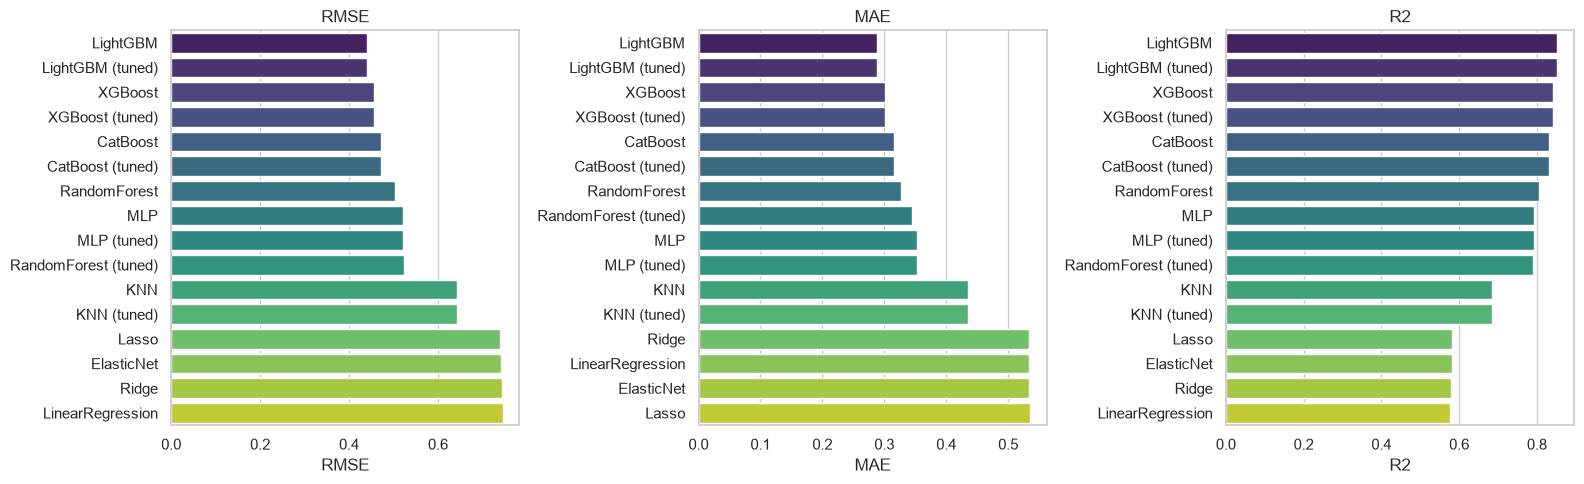

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    order = results_df.sort_values(metric, ascending=(metric != "R2")).index
    sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
    ax.set_title(metric)
    ax.set_ylabel("")

plt.tight_layout()
plt.show()


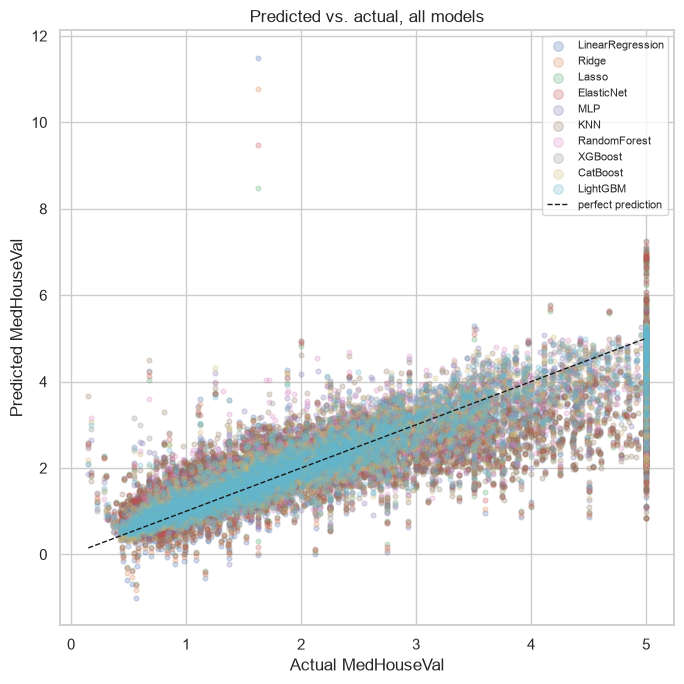

In [38]:
fig, ax = plt.subplots(figsize=(7, 7))
preds = {
    "LinearRegression": y_pred_lr,
    "Ridge": y_pred_ridge,
    "Lasso": y_pred_lasso,
    "ElasticNet": y_pred_elastic,
    "MLP": y_pred_mlp,
    "KNN": y_pred_knn,
    "RandomForest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "CatBoost": y_pred_cat,
    "LightGBM": y_pred_lgbm,
}
for name, p in preds.items():
    ax.scatter(y_test, p, alpha=0.25, s=12, label=name)

lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, "k--", linewidth=1, label="perfect prediction")
ax.set_xlabel("Actual MedHouseVal")
ax.set_ylabel("Predicted MedHouseVal")
ax.set_title("Predicted vs. actual, all models")
ax.legend(markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()


## 13. Stacking

Combine Random Forest, XGBoost and LightGBM with a linear meta-model. The meta-model learns from out-of-fold predictions within the training partition. Compare the resulting ensemble with the individual models on the held-out partition.

In [39]:
from sklearn.ensemble import StackingRegressor

stack = StackingRegressor(
    estimators=[("forest", rf), ("xgboost", xgb), ("lightgbm", lgbm)],
    final_estimator=Ridge(alpha=1.0),
    cv=2,
    n_jobs=2,
)
stack.fit(X_train_scaled, y_train)
y_pred_stack = stack.predict(X_test_scaled)
evaluate("Stacking", y_test, y_pred_stack)


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Stacking          RMSE=0.4410   MAE=0.2904   R2=0.8516


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


(0.44100361032693314, 0.29044104373365365, 0.8515851252923601)

## 14. Conclusion

Use the measured comparison to discuss accuracy, interpretability and training cost. Regularized linear models are useful references for correlated inputs. KNN depends on the distance representation. MLP needs scaling and optimization checks. Tree ensembles capture nonlinear interactions, and stacking adds a meta-model trained on out-of-fold predictions.

Report the best measured result together with its metric and validation design. Inspect errors within important target ranges or groups before choosing a model for a new population.

In [40]:
final_results = pd.DataFrame(results).T.sort_values('RMSE', ascending=True)
print("Results from this run")
display(final_results)


Results from this run


,RMSE,MAE,R2
LightGBM,0.439290,0.288344,0.852736
LightGBM (tuned),0.439290,0.288344,0.852736
Stacking,0.441004,0.290441,0.851585
XGBoost (tuned),0.455563,0.301812,0.841623
XGBoost,0.455563,0.301812,0.841623
CatBoost (tuned),0.471527,0.315155,0.830330
CatBoost,0.471527,0.315155,0.830330
RandomForest,0.503933,0.326294,0.806206
MLP,0.520519,0.352756,0.793240
MLP (tuned),0.520519,0.352756,0.793240
